In [1]:

import pandas as pd
import numpy as np
from pathlib import Path

# Load the retail sales dataset
data_path = Path("../data/processed/raw_sales.csv")
df = pd.read_csv(data_path)

# Convert the transaction date to datetime
df["transaction_date"] = pd.to_datetime(df["transaction_date"])

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nDate range:")
print(df["transaction_date"].min(), "to", df["transaction_date"].max())

print("\nFirst five rows:")
display(df.head())


Dataset loaded successfully!
Dataset shape: (10035, 20)

Date range:
2025-01-01 00:00:00 to 2025-12-31 00:00:00

First five rows:


,transaction_id,transaction_datetime,transaction_date,line_number,store_id,store_name,county,town,customer_id,product_id,product_name,product_category,quantity,unit_price_kes,gross_sales_kes,promotion,discount_rate,discount_amount_kes,net_sales_kes,payment_method
0,TXN004795,2025-01-01 07:19:00,2025-01-01,1,ST006,Jirani Mart - Ruiru,Kiambu,Ruiru,CUST00214,PR002,Rice 2kg,Food & Pantry,1,301.63,301.63,Weekend Offer,0.05,15.08,286.55,Cash
1,TXN004795,2025-01-01 07:19:00,2025-01-01,2,ST006,Jirani Mart - Ruiru,Kiambu,Ruiru,CUST00214,PR016,Bottled Water 1.5L,Beverages,2,79.87,159.74,Weekend Offer,0.00,0.00,159.74,Cash
2,TXN003214,2025-01-01 10:08:00,2025-01-01,1,ST018,Jirani Mart - Nyeri Town,Nyeri,Nyeri Town,CUST00091,PR010,Laundry Detergent 1kg,Household,6,243.59,1461.54,No Promotion,0.00,0.00,1461.54,Cash
3,TXN003214,2025-01-01 10:08:00,2025-01-01,2,ST018,Jirani Mart - Nyeri Town,Nyeri,Nyeri Town,CUST00091,PR009,Eggs Tray 30,Dairy & Chilled,2,494.63,989.26,No Promotion,0.00,0.00,989.26,Cash
4,TXN003375,2025-01-01 11:39:00,2025-01-01,1,ST012,Jirani Mart - Naivasha,Nakuru,Naivasha,CUST00515,PR014,Toothpaste 150ml,Personal Care,1,181.90,181.90,No Promotion,0.00,0.00,181.90,Debit/Credit Card


In [2]:

# Check missing values in important columns
print("Missing transaction dates:", df["transaction_date"].isna().sum())
print("Missing net sales:", df["net_sales_kes"].isna().sum())

# Remove records without a valid date or sales value
sales_df = df.dropna(
    subset=["transaction_date", "net_sales_kes"]
).copy()

# Convert sales values to numeric
sales_df["net_sales_kes"] = pd.to_numeric(
    sales_df["net_sales_kes"], errors="coerce"
)

sales_df = sales_df.dropna(subset=["net_sales_kes"])

# Aggregate product lines into daily total sales
daily_sales = (
    sales_df.groupby("transaction_date")["net_sales_kes"]
    .sum()
    .sort_index()
    .asfreq("D", fill_value=0)
)

daily_sales = daily_sales.rename("daily_sales_kes")

print("\nDaily sales dataset prepared.")
print("Number of days:", len(daily_sales))
print("First date:", daily_sales.index.min())
print("Last date:", daily_sales.index.max())
print("Average daily sales (KES):", round(daily_sales.mean(), 2))
print("Minimum daily sales (KES):", round(daily_sales.min(), 2))
print("Maximum daily sales (KES):", round(daily_sales.max(), 2))

display(daily_sales.head(10).to_frame())


Missing transaction dates: 0
Missing net sales: 0

Daily sales dataset prepared.
Number of days: 365
First date: 2025-01-01 00:00:00
Last date: 2025-12-31 00:00:00
Average daily sales (KES): 18428.19
Minimum daily sales (KES): 3191.68
Maximum daily sales (KES): 45704.67


,daily_sales_kes
transaction_date,
2025-01-01,13329.02
2025-01-02,22490.70
2025-01-03,26689.21
2025-01-04,18884.25
2025-01-05,11322.14
2025-01-06,18258.74
2025-01-07,15814.00
2025-01-08,8122.57
2025-01-09,28395.48


In [3]:

# Create a time-aware train-validation split
# First 9 months: training data
# Last 3 months: validation data

split_date = "2025-10-01"

train = daily_sales.loc[daily_sales.index < split_date]
validation = daily_sales.loc[daily_sales.index >= split_date]

# Baseline: predict each day's sales using the previous day's actual sales
baseline_predictions = daily_sales.shift(1).loc[validation.index]

# Calculate evaluation metrics
mae = np.mean(np.abs(validation - baseline_predictions))
rmse = np.sqrt(np.mean((validation - baseline_predictions) ** 2))

print("Training period:", train.index.min().date(), "to", train.index.max().date())
print("Training days:", len(train))
print("\nValidation period:", validation.index.min().date(), "to", validation.index.max().date())
print("Validation days:", len(validation))
print("\nBaseline Forecast Results")
print(f"MAE: KES {mae:,.2f}")
print(f"RMSE: KES {rmse:,.2f}")


Training period: 2025-01-01 to 2025-09-30
Training days: 273

Validation period: 2025-10-01 to 2025-12-31
Validation days: 92

Baseline Forecast Results
MAE: KES 7,489.73
RMSE: KES 9,120.31


In [5]:

%pip install scikit-learn


Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.4 MB ? eta -:--:--
   ----- ---------------------------------- 1.0/8.4 MB 1.9 MB/s eta 0:00:04
   -------- ------------------------------- 1.8/8.4 MB 2.6 MB/s eta 0:00:03
   ----------- ---------------------------- 2.4/8.4 MB 2.9 MB/s eta 0:00:03
   --------------- ------------------------ 3.1/8.4 MB 2.8 MB/s eta 0:00:02
   ----------------- ---------------------- 3.7/8.4 MB 2.7 MB/s eta 0:00:02
   -------------------- ------------------- 4.2/8.4 MB 2.7 MB/s eta 0:00:02
   --------------------- ------------------ 4.5/8.4 MB 2.8 MB/s eta 0:00:02
   ----------------------- ---------------- 5


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:

import sklearn

print("Scikit-learn version:", sklearn.__version__)
print("Installation successful!")


Scikit-learn version: 1.9.1
Installation successful!


In [7]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Build forecasting features using past sales only
model_data = daily_sales.to_frame()

model_data["lag_1"] = model_data["daily_sales_kes"].shift(1)
model_data["lag_7"] = model_data["daily_sales_kes"].shift(7)

model_data["rolling_mean_7"] = (
    model_data["daily_sales_kes"]
    .shift(1)
    .rolling(window=7)
    .mean()
)

model_data["day_of_week"] = model_data.index.dayofweek

model_data = model_data.dropna()

features = ["lag_1", "lag_7", "rolling_mean_7", "day_of_week"]
target = "daily_sales_kes"

# Time-aware train-validation split
train_model = model_data.loc[model_data.index < split_date]
valid_model = model_data.loc[model_data.index >= split_date]

X_train = train_model[features]
y_train = train_model[target]

X_valid = valid_model[features]
y_valid = valid_model[target]

# Train model
rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    min_samples_leaf=3
)

rf_model.fit(X_train, y_train)

# Generate validation predictions
rf_predictions = rf_model.predict(X_valid)

# Evaluate model
rf_mae = mean_absolute_error(y_valid, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_valid, rf_predictions))

print("Random Forest Forecast Results")
print(f"MAE: KES {rf_mae:,.2f}")
print(f"RMSE: KES {rf_rmse:,.2f}")
print(f"Validation days: {len(y_valid)}")


Random Forest Forecast Results
MAE: KES 6,097.06
RMSE: KES 7,729.64
Validation days: 92


In [8]:

# Compare baseline and Random Forest performance

comparison = pd.DataFrame({
    "Model": ["Naive Baseline", "Random Forest"],
    "MAE (KES)": [mae, rf_mae],
    "RMSE (KES)": [rmse, rf_rmse]
})

comparison["MAE Improvement (%)"] = [
    0,
    (mae - rf_mae) / mae * 100
]

comparison["RMSE Improvement (%)"] = [
    0,
    (rmse - rf_rmse) / rmse * 100
]

display(comparison.round(2))


,Model,MAE (KES),RMSE (KES),MAE Improvement (%),RMSE Improvement (%)
0,Naive Baseline,7489.73,9120.31,0.00,0.00
1,Random Forest,6097.06,7729.64,18.59,15.25


In [9]:

comparison.style.format({
    "MAE (KES)": "{:,.2f}",
    "RMSE (KES)": "{:,.2f}",
    "MAE Improvement (%)": "{:.2f}%",
    "RMSE Improvement (%)": "{:.2f}%"
}).hide(axis="index")


Model,MAE (KES),RMSE (KES),MAE Improvement (%),RMSE Improvement (%)
Naive Baseline,"7,489.73","9,120.31",0.00%,0.00%
Random Forest,"6,097.06","7,729.64",18.59%,15.25%


In [10]:

# Compare actual sales with Random Forest predictions

forecast_results = pd.DataFrame({
    "Actual Sales (KES)": y_valid,
    "Predicted Sales (KES)": rf_predictions
})

forecast_results["Error (KES)"] = (
    forecast_results["Actual Sales (KES)"]
    - forecast_results["Predicted Sales (KES)"]
)

forecast_results["Absolute Error (KES)"] = (
    forecast_results["Error (KES)"].abs()
)

# Show the 10 days with the largest errors
largest_errors = forecast_results.sort_values(
    "Absolute Error (KES)", ascending=False
).head(10)

display(largest_errors.round(2))


,Actual Sales (KES),Predicted Sales (KES),Error (KES),Absolute Error (KES)
transaction_date,,,,
2025-10-21,42269.08,17800.09,24468.99,24468.99
2025-10-01,39180.94,16835.42,22345.52,22345.52
2025-11-20,32928.57,13117.13,19811.44,19811.44
2025-10-22,31254.29,14173.67,17080.62,17080.62
2025-12-10,9132.05,24749.64,-15617.59,15617.59
2025-12-25,28640.81,14439.91,14200.90,14200.90
2025-10-20,33608.53,20188.31,13420.22,13420.22
2025-12-31,30219.21,17079.39,13139.82,13139.82
2025-10-17,11650.28,23732.82,-12082.54,12082.54


### Prediction Error Analysis

The Random Forest model performed better than the naive baseline on the validation dataset. Its Mean Absolute Error (MAE) was KES 6,097.06, compared with KES 7,489.73 for the baseline, representing an 18.59% improvement. Its Root Mean Squared Error (RMSE) was KES 7,729.64, compared with KES 9,120.31, representing a 15.25% improvement.

However, the model still made substantial errors on individual days. On 21 October 2025, actual sales were KES 42,269.08, while the model predicted KES 17,800.09. On 10 December 2025, actual sales were KES 9,132.05, while the model predicted KES 24,749.64.

These examples show that the model sometimes underestimates high-sales days and overestimates low-sales days. Its features, which use previous sales values and the day of the week, may not capture every unusual sales event.

Further investigation into promotions, public holidays, stock availability and other factors could help explain these errors. These are possible explanations, not confirmed causes.

Overall, the Random Forest improved on the baseline, but its predictions are not always reliable for individual days.

In [11]:

# Check whether any dates in the daily sales series have zero sales

zero_sales_dates = daily_sales[daily_sales == 0]

print("Total calendar days:", len(daily_sales))
print("Days with zero recorded sales:", len(zero_sales_dates))

if len(zero_sales_dates) > 0:
    print("\nDates with zero sales:")
    display(zero_sales_dates.to_frame())
else:
    print("Every date has positive recorded sales.")

# Check whether the original dataset contains records for every date
original_dates = pd.to_datetime(
    sales_df["transaction_date"]
).dt.normalize().nunique()

print("\nDistinct dates in original sales data:", original_dates)


Total calendar days: 365
Days with zero recorded sales: 0
Every date has positive recorded sales.

Distinct dates in original sales data: 365


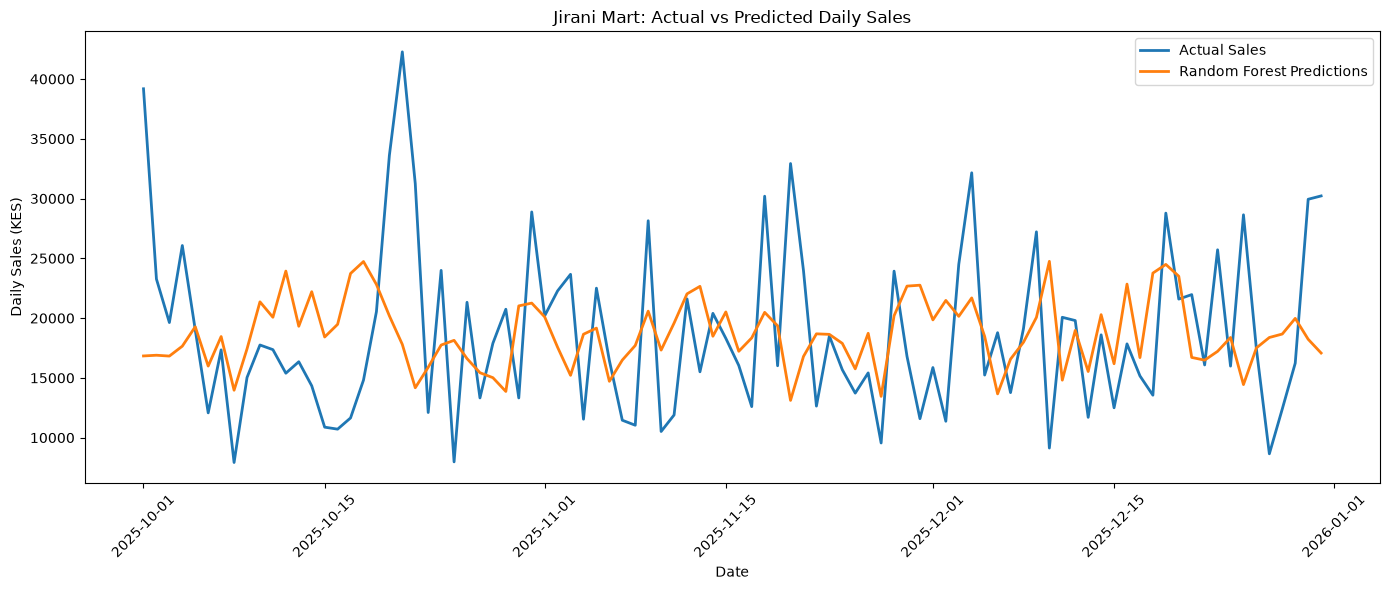

In [12]:

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    y_valid.index,
    y_valid.values,
    label="Actual Sales",
    linewidth=2
)

plt.plot(
    y_valid.index,
    rf_predictions,
    label="Random Forest Predictions",
    linewidth=2
)

plt.title("Jirani Mart: Actual vs Predicted Daily Sales")
plt.xlabel("Date")
plt.ylabel("Daily Sales (KES)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### Actual vs. Predicted Sales

The line chart compares actual daily sales with predictions from the Random Forest model for October to December 2025.

The model captures some changes in daily sales but does not consistently predict sudden increases and decreases. It tends to underestimate some high-sales days and overestimate some low-sales days.

This suggests that the model's current features, including previous-day sales, sales from seven days earlier, the seven-day rolling average, and day of the week, do not fully explain daily sales fluctuations.

Additional features, such as promotions, public holidays and product-level demand, could potentially improve the model. However, their usefulness would need to be tested through further model evaluation.

Overall, the Random Forest performed better than the naive baseline, reducing MAE by 18.59% and RMSE by 15.25%. Nevertheless, the graph shows that substantial prediction errors remain.

,Feature,Importance
2,rolling_mean_7,0.3446
1,lag_7,0.2915
0,lag_1,0.2615
3,day_of_week,0.1024


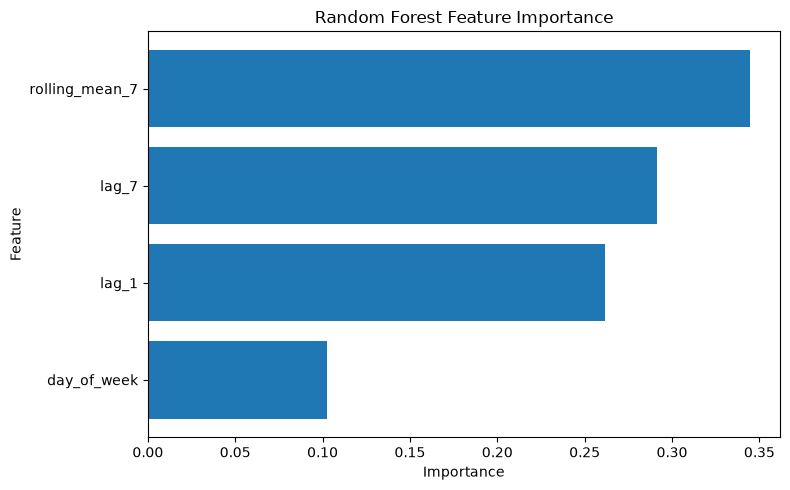

In [13]:

# Identify the most important features in the Random Forest

feature_importance = pd.DataFrame({
    "Feature": features,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "Importance", ascending=False
)

display(feature_importance.round(4))

# Plot feature importance
plt.figure(figsize=(8, 5))
plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


### Feature Importance Analysis

The Random Forest feature-importance analysis showed that the seven-day rolling average was the most important feature, with an importance score of 0.3446 (34.46%). Sales from seven days earlier followed at 0.2915 (29.15%), while sales from the previous day contributed 0.2615 (26.15%). The day of the week had the lowest importance at 0.1024 (10.24%).

These results suggest that recent sales history was more useful to the model than the day-of-week feature when predicting daily sales. However, feature importance indicates how the model used its inputs; it does not establish causation or prove that these relationships will remain the same in future periods.

## Milestone 6: Predictive Modelling and Evaluation

### 1. Objective

The objective was to develop a daily sales forecasting model for Jirani Mart using historical retail sales data from 2025.

### 2. What Was Built

- Prepared daily sales data from item-level transaction records.
- Created a naive baseline forecast using the previous day's sales.
- Developed a Random Forest regression model using historical sales features.
- Split the data chronologically into training and validation periods.
- Evaluated both models using Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE).
- Compared model performance and analysed prediction errors.
- Visualised actual versus predicted sales.
- Examined feature importance to understand which inputs the model relied on most.

### 3. Model Evaluation

The model was trained using data from January to September 2025 and evaluated on October to December 2025.

| Metric | Naive Baseline | Random Forest |
|---|---:|---:|
| MAE | KES 7,489.73 | KES 6,097.06 |
| RMSE | KES 9,120.31 | KES 7,729.64 |

The Random Forest reduced MAE by 18.59% and RMSE by 15.25% compared with the baseline.

### 4. Feature Importance

The seven-day rolling average was the most important feature (34.46%), followed by sales seven days earlier (29.15%), sales from the previous day (26.15%), and day of the week (10.24%).

These results suggest that recent sales history was useful for predicting daily sales.

### 5. Prediction Errors and Limitations

The model sometimes underestimated high-sales days and overestimated low-sales days. For example, on 21 October 2025, actual sales were KES 42,269.08, while predicted sales were KES 17,800.09.

The model uses previous sales values and the day of the week but does not currently include promotions, holidays, stock availability, or other external factors.

The validation evaluates one-day-ahead predictions using actual previous-day sales. It does not evaluate a forecast of the entire future period generated in advance. The results cover one year of simulated retail data, so performance on future real-world sales may differ.

### 6. Conclusion

The Random Forest performed better than the naive baseline on the validation period. However, substantial errors remain, particularly during unusual sales peaks and drops. Additional features and further validation on future data may improve forecasting performance.
